In [ ]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns',None)

In [ ]:
#Assignment1
#Business Problem

'''Predict whether a person earns:

<=50K

50K'''

#Business Objective

'''Help organizations identify income groups for targeted marketing,
loan approval, insurance segmentation, etc.'''

#Constraints
'''High accuracy required
Class imbalance may exist'''

In [ ]:
train = pd.read_csv('/content/SalaryData_Train.csv')
test = pd.read_csv('/content/SalaryData_Test.csv')

print(train.shape)
print(test.shape)

train.head()

(30161, 14)
(15060, 14)


,age,workclass,education,educationno,maritalstatus,occupation,relationship,race,sex,capitalgain,capitalloss,hoursperweek,native,Salary
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
#data dictionary
data_dict = pd.DataFrame({
    "Column":train.columns,
    "Datatype":train.dtypes.values,
    "Missing Values":train.isnull().sum().values
})

data_dict

,Column,Datatype,Missing Values
0,age,int64,0
1,workclass,object,0
2,education,object,0
3,educationno,int64,0
4,maritalstatus,object,0
5,occupation,object,0
6,relationship,object,0
7,race,object,0
8,sex,object,0
9,capitalgain,int64,0


In [ ]:
#EDA
train.info()

train.describe()

train.describe(include='object')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30161 entries, 0 to 30160
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   age            30161 non-null  int64 
 1   workclass      30161 non-null  object
 2   education      30161 non-null  object
 3   educationno    30161 non-null  int64 
 4   maritalstatus  30161 non-null  object
 5   occupation     30161 non-null  object
 6   relationship   30161 non-null  object
 7   race           30161 non-null  object
 8   sex            30161 non-null  object
 9   capitalgain    30161 non-null  int64 
 10  capitalloss    30161 non-null  int64 
 11  hoursperweek   30161 non-null  int64 
 12  native         30161 non-null  object
 13  Salary         30161 non-null  object
dtypes: int64(5), object(9)
memory usage: 3.2+ MB


,workclass,education,maritalstatus,occupation,relationship,race,sex,native,Salary
count,30161,30161,30161,30161,30161,30161,30161,30161,30161
unique,7,16,7,14,6,5,2,40,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,22285,9840,14065,4038,12463,25932,20380,27504,22653


In [ ]:
#1MBD
train.mean(numeric_only=True)

#2MBD
train.var(numeric_only=True)

train.std(numeric_only=True)

#3MBD
train.skew(numeric_only=True)

#4MBD
train.skew(numeric_only=True)

,0
age,0.530180
educationno,-0.305378
capitalgain,11.902483
capitalloss,4.528238
hoursperweek,0.330856


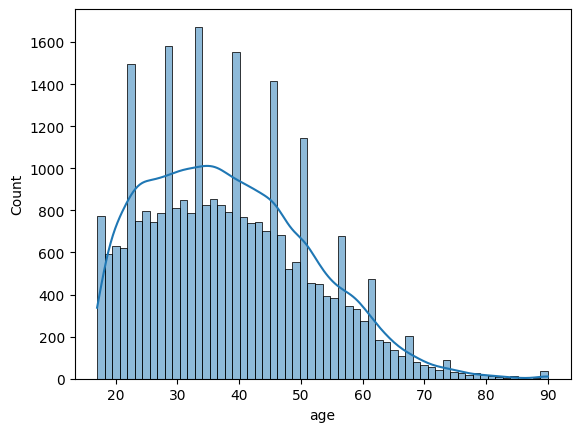

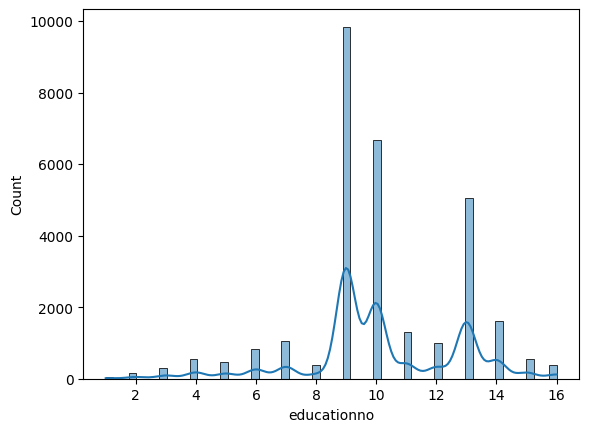

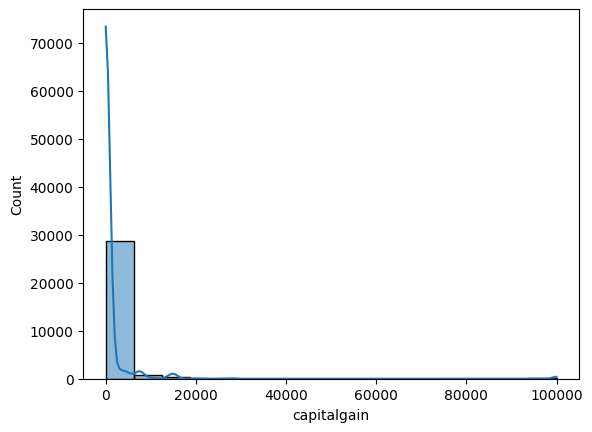

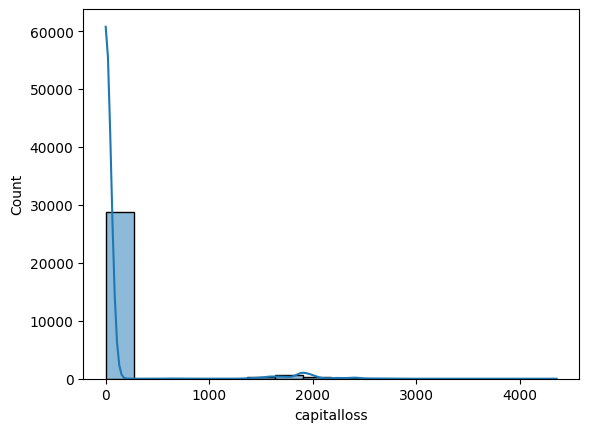

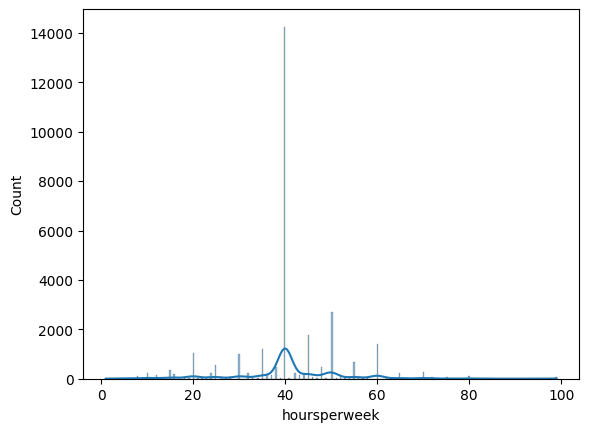

In [ ]:
#uniavriate analysis
for col in train.select_dtypes(include=np.number).columns:
    sns.histplot(train[col],kde=True)
    plt.show()

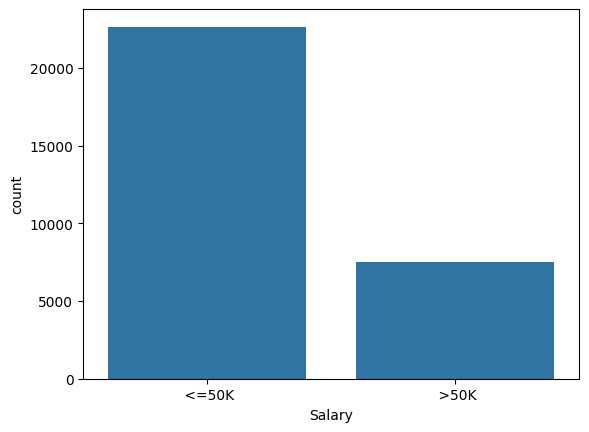

Salary,<=50K,>50K
education,,
10th,761,59
11th,989,59
12th,348,29
1st-4th,145,6
5th-6th,276,12
7th-8th,522,35
9th,430,25
Assoc-acdm,752,256
Assoc-voc,963,344


In [ ]:
#bivariate analysis
sns.countplot(x='Salary',data=train)
plt.show()

pd.crosstab(train['education'],train['Salary'])

In [ ]:
#preprocessing
combined = pd.concat([train,test],axis=0)

le = LabelEncoder()

for col in combined.columns:
    if combined[col].dtype=='object':
        combined[col] = le.fit_transform(combined[col])

train_new = combined.iloc[:len(train)]
test_new = combined.iloc[len(train):]

X_train = train_new.drop('Salary',axis=1)
y_train = train_new['Salary']

X_test = test_new.drop('Salary',axis=1)
y_test = test_new['Salary']

In [ ]:
#model building
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()

gnb.fit(X_train,y_train)

pred = gnb.predict(X_test)

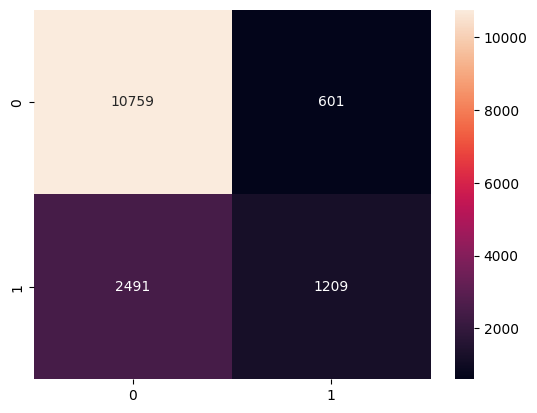

              precision    recall  f1-score   support

           0       0.81      0.95      0.87     11360
           1       0.67      0.33      0.44      3700

    accuracy                           0.79     15060
   macro avg       0.74      0.64      0.66     15060
weighted avg       0.78      0.79      0.77     15060

Accuracy: 0.7946879150066402
Precision: 0.6679558011049723
Recall: 0.32675675675675675
F1: 0.43883847549909255


In [ ]:
#model evalustion
cm = confusion_matrix(y_test,pred)

sns.heatmap(cm,annot=True,fmt='d')
plt.show()

print(classification_report(y_test,pred))

print("Accuracy:",accuracy_score(y_test,pred))
print("Precision:",precision_score(y_test,pred))
print("Recall:",recall_score(y_test,pred))
print("F1:",f1_score(y_test,pred))

In [ ]:
#hyper parameter tunning
var_smoothing = [1e-9,1e-8,1e-7,1e-6]

best_acc = 0

for v in var_smoothing:

    model = GaussianNB(var_smoothing=v)

    model.fit(X_train,y_train)

    pred = model.predict(X_test)

    acc = accuracy_score(y_test,pred)

    print(v,acc)

    if acc > best_acc:
        best_acc = acc
        best_model = model

print(best_acc)

1e-09 0.7946879150066402
1e-08 0.7908366533864541
1e-07 0.7887782204515272
1e-06 0.7884462151394422
0.7946879150066402


In [ ]:
#Business Impact
'''Income prediction
Loan targeting
Customer segmentation
Insurance pricing'''

In [ ]:
#Assignment2
df = pd.read_csv('/content/NB_Car_Ad.csv')

df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [ ]:
#data dict
pd.DataFrame({
    'Column':df.columns,
    'Datatype':df.dtypes
})

,Column,Datatype
User ID,User ID,int64
Gender,Gender,object
Age,Age,int64
EstimatedSalary,EstimatedSalary,int64
Purchased,Purchased,int64


In [ ]:
#drop user ID
df.drop('User ID',axis=1,inplace=True)

In [ ]:
#EDA
df.describe()

df['Purchased'].value_counts()

,count
Purchased,
0,257
1,143


In [ ]:
#1MBD
df.mean(numeric_only=True)
#2MBD
df.var(numeric_only=True)
#3MBD
df.skew(numeric_only=True)
#4MBD
df.kurt(numeric_only=True)

,0
Age,-0.622513
EstimatedSalary,-0.405878
Purchased,-1.651992


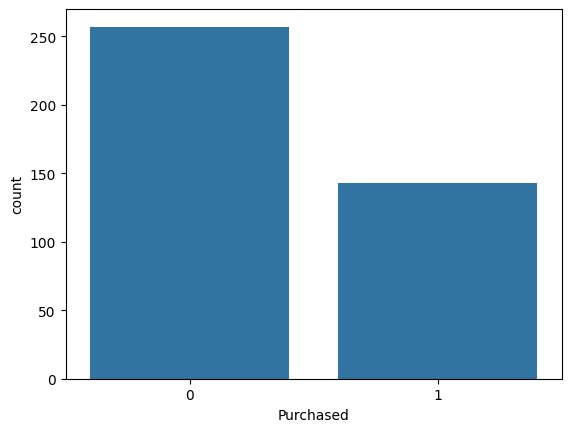

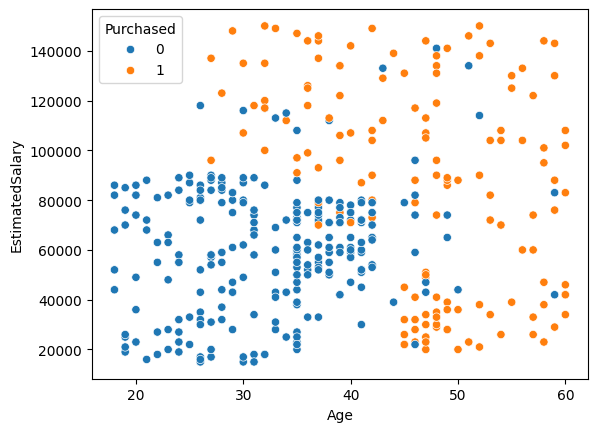

In [ ]:
#visualization
sns.countplot(x='Purchased',data=df)
plt.show()

sns.scatterplot(
    x='Age',
    y='EstimatedSalary',
    hue='Purchased',
    data=df
)
plt.show()

In [ ]:
#encoding
df['Gender'] = LabelEncoder().fit_transform(df['Gender'])

In [ ]:
#Bernoulli Requirement
df['Age'] = (df['Age']>df['Age'].median()).astype(int)

df['EstimatedSalary'] = (
    df['EstimatedSalary']>
    df['EstimatedSalary'].median()
).astype(int)

In [ ]:
#train-test-split
X = df.drop('Purchased',axis=1)

y = df['Purchased']

X_train,X_test,y_train,y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=100
)

In [ ]:
#bernoulli naive bayes
from sklearn.naive_bayes import BernoulliNB

bnb = BernoulliNB()

bnb.fit(X_train,y_train)

pred = bnb.predict(X_test)

In [ ]:
#evalustion
print(confusion_matrix(y_test,pred))

print(classification_report(y_test,pred))

print("Accuracy:",accuracy_score(y_test,pred))

[[42  7]
 [18 13]]
              precision    recall  f1-score   support

           0       0.70      0.86      0.77        49
           1       0.65      0.42      0.51        31

    accuracy                           0.69        80
   macro avg       0.68      0.64      0.64        80
weighted avg       0.68      0.69      0.67        80

Accuracy: 0.6875


In [ ]:
#Business Impact
'''Identify customers likely to purchase SUV
Reduce advertising cost
Improve campaign conversion'''

In [ ]:
#Assignment3
#Business Problem

'''Predict:

1 = Real Disaster
0 = Fake Disaster'''

In [ ]:
df = pd.read_csv('/content/Disaster_tweets_NB.csv')

df.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [ ]:
df.isnull().sum()

,0
id,0
keyword,61
location,2533
text,0
target,0


In [ ]:
#text cleaning
import re

def clean_text(text):

    text = str(text).lower()

    text = re.sub(r"http\\S+","",text)

    text = re.sub(r"[^a-zA-Z ]","",text)

    return text

df['clean_text'] = df['text'].apply(clean_text)

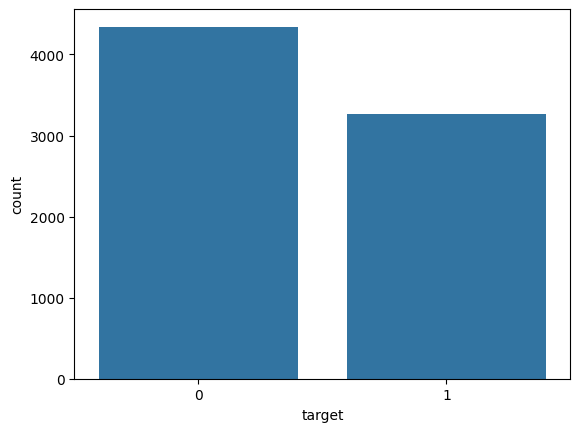

In [ ]:
#EDA
df['target'].value_counts()

sns.countplot(x='target',data=df)
plt.show()

In [ ]:
#TFIDF Vectorization
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=5000
)

X = tfidf.fit_transform(df['clean_text'])

y = df['target']

In [ ]:
#split data
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
#multinominal naive bayes
from sklearn.naive_bayes import MultinomialNB

mnb = MultinomialNB()

mnb.fit(X_train,y_train)

pred = mnb.predict(X_test)

In [ ]:
#evaluation
print(confusion_matrix(y_test,pred))

print(classification_report(y_test,pred))

print("Accuracy:",accuracy_score(y_test,pred))

[[769 105]
 [209 440]]
              precision    recall  f1-score   support

           0       0.79      0.88      0.83       874
           1       0.81      0.68      0.74       649

    accuracy                           0.79      1523
   macro avg       0.80      0.78      0.78      1523
weighted avg       0.80      0.79      0.79      1523

Accuracy: 0.793827971109652


In [ ]:
#hyperparameter tunning
alphas = [0.1,0.5,1,2]

best = 0

for a in alphas:

    model = MultinomialNB(alpha=a)

    model.fit(X_train,y_train)

    pred = model.predict(X_test)

    acc = accuracy_score(y_test,pred)

    print(a,acc)

    if acc > best:
        best = acc

print(best)

0.1 0.7912015758371634
0.5 0.7905449770190414
1 0.793827971109652
2 0.7892317793827971
0.793827971109652


In [ ]:
#Business Impact
'''Disaster monitoring
Emergency response prioritization
Fake-news detection'''

In [ ]:
#Assignment4
#Business Problem

'''Classify SMS as:

Ham
Spam'''

In [ ]:
df = pd.read_csv(
    '/content/sms_raw_NB.csv',
    encoding='latin1'
)

df.head()

,type,text
0,ham,Hope you are having a good week. Just checking in
1,ham,K..give back my thanks.
2,ham,Am also doing in cbe only. But have to pay.
3,spam,"complimentary 4 STAR Ibiza Holiday or å£10,000..."
4,spam,okmail: Dear Dave this is your final notice to...


In [ ]:
#Rename col
df.columns=['target','text']

In [ ]:
#text cleaning
import re

def clean_text(text):

    text = text.lower()

    text = re.sub(r'[^a-zA-Z ]','',text)

    return text

df['clean_text'] = df['text'].apply(clean_text)

In [ ]:
#encode target
df['target'] = df['target'].map({
    'ham':0,
    'spam':1
})

In [ ]:
#TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=3000
)

X = tfidf.fit_transform(df['clean_text'])

y = df['target']

In [ ]:
#split
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
#multinominal NB
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train,y_train)

pred = model.predict(X_test)

In [ ]:
#Evaluation
print(confusion_matrix(y_test,pred))

print(classification_report(y_test,pred))

print("Accuracy:",accuracy_score(y_test,pred))

[[961   2]
 [ 28 121]]
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       963
           1       0.98      0.81      0.89       149

    accuracy                           0.97      1112
   macro avg       0.98      0.91      0.94      1112
weighted avg       0.97      0.97      0.97      1112

Accuracy: 0.9730215827338129
